# Lab 2: Spam Classification and Airbnb Price Outliers

**Name:** Sukhchain Singh  
**Student ID:** 9111541  
**Course:** CSCN8000 – Artificial Intelligence Algorithms and Mathematics

## Introduction

This lab has two parts.

In Part A, I will use the provided dataset to train Gaussian Naive Bayes
and Multinomial Naive Bayes models. I will compare their results and
use them to make predictions on test data.

In Part B, I will examine Airbnb prices in New York City. I will compare
different methods for identifying unusual prices and explain the rule
I use to create a cleaned dataset.

## Part A: Load and Explore the Dataset

First, I will load the dataset and look at the first five rows.
This will help me understand the columns before preparing the data
for the models.

I will use pandas, a Python library that helps us work with data
in rows and columns.

In [1]:
import pandas as pd

# Load the dataset
data = pd.read_csv("../../practical_labs/Lab2_dataset.csv")

# Display the first five rows
data.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


### Understanding and Checking the Data

Each row contains an email. The text column contains the email message,
and label_num tells us whether it is not spam (0) or spam (1).
The word "ham" means an email that is not spam.

I will use text as the input and label_num as the target.
I will not use label as an input because it already contains the answer.

Before training, I will check the dataset size, missing values,
class counts, and repeated email messages. These checks will help me
decide whether any cleaning is needed.

In [2]:
# Check the number of rows and columns
print("Dataset shape:", data.shape)

# Check for missing information
print("\nMissing values:")
print(data.isnull().sum())

# Count spam and non-spam emails
print("\nNumber of emails in each class:")
print(data["label"].value_counts())

# Check whether email messages are repeated
print("\nRepeated email texts:")
print(data["text"].duplicated().sum())

Dataset shape: (5171, 4)

Missing values:
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64

Number of emails in each class:
label
ham     3672
spam    1499
Name: count, dtype: int64

Repeated email texts:
178


### Initial Observations

The dataset contains 5,171 emails and 4 columns.
There are 3,672 non-spam emails and 1,499 spam emails.
This means the dataset has more non-spam emails than spam emails.

No missing values were found. However, there are 178 repeated email
texts. I will remove repeated messages before splitting the data so
that the same email text does not appear in both training and testing.

Before removing duplicates, I will also check whether any identical
messages have different target labels.

In [3]:
# Check whether the same email text has different answers
labels_per_email = data.groupby("text")["label_num"].nunique()

print("Email texts with conflicting labels:")
print((labels_per_email > 1).sum())

# Keep one copy of each email message
clean_data = data.drop_duplicates(subset=["text"]).copy()

print("\nRows before cleaning:", len(data))
print("Rows after cleaning:", len(clean_data))

print("\nClass counts after cleaning:")
print(clean_data["label"].value_counts())

Email texts with conflicting labels:
0

Rows before cleaning: 5171
Rows after cleaning: 4993

Class counts after cleaning:
label
ham     3531
spam    1462
Name: count, dtype: int64


### Cleaning Results

After removing 178 repeated messages, the dataset contains 4,993 emails:
3,531 non-spam emails and 1,462 spam emails.

No identical email texts had conflicting target labels.

### Splitting the Data

I will use the email text as the input (X) and label_num as the target (y).

I will split the data into 80% training data and 20% test data.
The training data will help the models learn. The test data will
check their predictions on emails they did not see during training.

I will use stratify=y to keep approximately the same proportion
of spam and non-spam emails in both sets. Both models will use
the same training and test sets.

In [4]:
from sklearn.model_selection import train_test_split

# Inputs: the email messages
X = clean_data["text"]

# Targets: 0 means not spam, 1 means spam
y = clean_data["label_num"]

# Use 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Test emails:", len(X_test))

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTest class counts:")
print(y_test.value_counts())

Training emails: 3994
Test emails: 999

Training class counts:
label_num
0    2825
1    1169
Name: count, dtype: int64

Test class counts:
label_num
0    706
1    293
Name: count, dtype: int64


### Converting Email Text into Numbers

The models need numerical inputs, so I will use CountVectorizer
to convert the email messages into word counts.

Each row will represent an email, and each column will represent
a word in the vocabulary. The values will show how many times
each word appears in an email.

I will keep up to 2,000 words with the highest total counts in the
training emails. This keeps the example manageable, especially
when preparing data for Gaussian Naive Bayes.

I will learn the vocabulary from the training data only.
I will then use the same vocabulary to transform the test data.
This prevents information from the test set from influencing
the vocabulary.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

# Keep up to 2,000 vocabulary words
vectorizer = CountVectorizer(max_features=2000)

# Learn the vocabulary and count words in training emails
X_train_counts = vectorizer.fit_transform(X_train)

# Count words in test emails using the training vocabulary
X_test_counts = vectorizer.transform(X_test)

print("Training data shape:", X_train_counts.shape)
print("Test data shape:", X_test_counts.shape)

print("\nFirst 20 vocabulary words:")
print(vectorizer.get_feature_names_out()[:20])

Training data shape: (3994, 2000)
Test data shape: (999, 2000)

First 20 vocabulary words:
['00' '000' '000000' '01' '012' '02' '027' '03' '0310041' '04' '0424040'
 '0435' '05' '06' '07' '08' '09' '098' '0986725' '10']


### Training and Testing the Models

I will train Gaussian Naive Bayes and Multinomial Naive Bayes
using the same training emails and word-count features.

Gaussian Naive Bayes assumes that each feature follows a normal
(bell-shaped) distribution within each class. This assumption may
not fit word counts well.

Multinomial Naive Bayes works with non-negative count features,
such as the number of times words appear in emails.

After training, I will predict the labels of the test emails.
I will first compare accuracy, which is the proportion of
predictions that are correct. Later, I will also check how well
the models identify spam, because the classes are not balanced.

In [6]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score

# GaussianNB needs a dense array instead of a sparse matrix
X_train_dense = X_train_counts.toarray()
X_test_dense = X_test_counts.toarray()

# Train Gaussian Naive Bayes
gaussian_model = GaussianNB()
gaussian_model.fit(X_train_dense, y_train)

# Predict the test labels
gaussian_predictions = gaussian_model.predict(X_test_dense)

# Train Multinomial Naive Bayes
multinomial_model = MultinomialNB()
multinomial_model.fit(X_train_counts, y_train)

# Predict the test labels
multinomial_predictions = multinomial_model.predict(X_test_counts)

# Check accuracy
gaussian_accuracy = accuracy_score(y_test, gaussian_predictions)
multinomial_accuracy = accuracy_score(y_test, multinomial_predictions)

print("GaussianNB accuracy:", round(gaussian_accuracy, 4))
print("MultinomialNB accuracy:", round(multinomial_accuracy, 4))

GaussianNB accuracy: 0.9459
MultinomialNB accuracy: 0.9419


### Initial Model Comparison

Gaussian Naive Bayes achieved approximately 94.59% test accuracy,
while Multinomial Naive Bayes achieved approximately 94.19%.

Gaussian Naive Bayes performed slightly better based on accuracy,
with about 0.40 percentage points higher accuracy. This represents
four more correct predictions on the 999 test emails.

This result applies to this train-test split and these features.
It does not mean Gaussian Naive Bayes will always perform better.

### Checking the Prediction Errors

I will use confusion matrices to see how many spam and non-spam
emails each model classified correctly or incorrectly.

I will also examine precision, recall, and F1-score for spam:

- Precision: Of the emails predicted as spam, how many were actually spam?
- Recall: Of all the actual spam emails, how many did the model detect?
- F1-score: A score that balances precision and recall.

In [7]:
from sklearn.metrics import confusion_matrix, classification_report

# Gaussian model results
gaussian_matrix = pd.DataFrame(
    confusion_matrix(y_test, gaussian_predictions, labels=[0, 1]),
    index=["Actual not spam", "Actual spam"],
    columns=["Predicted not spam", "Predicted spam"]
)

print("GaussianNB confusion matrix:")
display(gaussian_matrix)

print("GaussianNB classification report:")
print(classification_report(
    y_test,
    gaussian_predictions,
    labels=[0, 1],
    target_names=["Not spam", "Spam"],
    zero_division=0
))

# Multinomial model results
multinomial_matrix = pd.DataFrame(
    confusion_matrix(y_test, multinomial_predictions, labels=[0, 1]),
    index=["Actual not spam", "Actual spam"],
    columns=["Predicted not spam", "Predicted spam"]
)

print("MultinomialNB confusion matrix:")
display(multinomial_matrix)

print("MultinomialNB classification report:")
print(classification_report(
    y_test,
    multinomial_predictions,
    labels=[0, 1],
    target_names=["Not spam", "Spam"],
    zero_division=0
))

GaussianNB confusion matrix:


,Predicted not spam,Predicted spam
Actual not spam,663,43
Actual spam,11,282


GaussianNB classification report:
              precision    recall  f1-score   support

    Not spam       0.98      0.94      0.96       706
        Spam       0.87      0.96      0.91       293

    accuracy                           0.95       999
   macro avg       0.93      0.95      0.94       999
weighted avg       0.95      0.95      0.95       999

MultinomialNB confusion matrix:


,Predicted not spam,Predicted spam
Actual not spam,660,46
Actual spam,12,281


MultinomialNB classification report:
              precision    recall  f1-score   support

    Not spam       0.98      0.93      0.96       706
        Spam       0.86      0.96      0.91       293

    accuracy                           0.94       999
   macro avg       0.92      0.95      0.93       999
weighted avg       0.95      0.94      0.94       999



### Model Results and Interpretation

Gaussian Naive Bayes achieved 94.59% accuracy, compared with
94.19% for Multinomial Naive Bayes.

Gaussian Naive Bayes correctly classified 945 of the 999 test emails.
It detected 282 spam emails and missed 11. It also incorrectly
classified 43 genuine emails as spam.

Multinomial Naive Bayes correctly classified 941 test emails.
It detected 281 spam emails and missed 12. It incorrectly
classified 46 genuine emails as spam.

For spam, Gaussian Naive Bayes had approximately 87% precision
and 96% recall. This means most emails it flagged were actually
spam, and it detected most of the spam in the test set.

I would choose Gaussian Naive Bayes for this experiment because
it had higher accuracy, fewer missed spam emails, and fewer
genuine emails incorrectly flagged as spam.

The difference was small. These results apply to this particular
split and the selected 2,000 word-count features. They do not
prove that Gaussian Naive Bayes is always the better model.

### Example Predictions on Test Emails

I will display ten test emails with their actual labels and
the predictions from both models.

The predictions were made using the email text without giving
the models the actual test labels. I am displaying the actual
labels now so I can compare the answers.

In [8]:
# Put the test emails, actual answers, and predictions together
prediction_examples = pd.DataFrame({
    "Email preview": X_test.str.slice(0, 100).to_numpy(),
    "Actual": y_test.to_numpy(),
    "Gaussian prediction": gaussian_predictions,
    "Multinomial prediction": multinomial_predictions
})

# Replace numbers with readable labels
label_names = {0: "Not spam", 1: "Spam"}

prediction_examples["Actual"] = prediction_examples["Actual"].map(label_names)

prediction_examples["Gaussian prediction"] = (
    prediction_examples["Gaussian prediction"].map(label_names)
)

prediction_examples["Multinomial prediction"] = (
    prediction_examples["Multinomial prediction"].map(label_names)
)

# Show the first ten test examples
display(prediction_examples.head(10))

,Email preview,Actual,Gaussian prediction,Multinomial prediction
0,"Subject: frontrea plant , gas\nwhen : wednesda...",Not spam,Spam,Not spam
1,Subject: news\nat least two bids seen for enro...,Not spam,Not spam,Not spam
2,"Subject: quailty web solutions , involutory\no...",Spam,Spam,Spam
3,Subject: txu fuels / sds nomination for decemb...,Not spam,Not spam,Not spam
4,Subject: use the links to get more information...,Spam,Spam,Spam
5,Subject: paliourg get the doctors time 4 freee...,Spam,Spam,Spam
6,Subject: registration confirmation from spinne...,Not spam,Spam,Spam
7,Subject: re : resume attached\nliz is an mit g...,Not spam,Not spam,Not spam
8,Subject: meter 981594 for jan\nthe meter shows...,Not spam,Not spam,Not spam
9,"Subject: the investor ' s toolbox\nmcintyre ,\...",Spam,Spam,Spam


### Observations from Example Predictions

In the first ten test examples, Gaussian Naive Bayes made two
incorrect predictions, while Multinomial Naive Bayes made one.

For example, Gaussian Naive Bayes incorrectly flagged the email
at row 0 as spam, while Multinomial Naive Bayes classified it correctly.
Both models incorrectly flagged the genuine email at row 6 as spam.

This shows that a model with higher overall accuracy can still
make mistakes on individual emails. I based my final comparison
on all 999 test emails, rather than only these ten examples.

## Part B: Airbnb Price Outliers

In this part, I will examine the nightly prices of Airbnb listings
in New York City.

An outlier is a value that is unusually far from other values
under a chosen rule. An unusually high price is not automatically
an error; it could represent a luxury property.

I will inspect the prices, compare different outlier-detection
methods, and explain the rule used to create a cleaned dataset.

### Loading and Checking the Dataset

First, I will load the Airbnb dataset and inspect its columns,
price summary, missing prices, and prices that are zero or negative.

In [9]:
# Load the Airbnb dataset
airbnb = pd.read_csv("../../practical_labs/AB_NYC_2019.csv")

print("Dataset shape:", airbnb.shape)

# Look at the first five listings
display(airbnb.head())

# Summarize nightly prices
print("\nPrice summary:")
print(airbnb["price"].describe())

print("\nMissing prices:", airbnb["price"].isnull().sum())
print("Zero or negative prices:", (airbnb["price"] <= 0).sum())

Dataset shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



Price summary:
count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

Missing prices: 0
Zero or negative prices: 11


### Initial Price Observations

The dataset contains 48,895 listings. The mean nightly price is
approximately $152.72, while the median is $106.

The mean is higher than the median, suggesting that some expensive
listings pull the average upward. The maximum price is $10,000.

There are no missing prices, but 11 listings have a price of zero.
I will exclude these listings because this analysis focuses on
paid nightly stays. I cannot determine from the price alone
whether these values are errors or have another explanation.

### Preparing and Visualizing Prices

I will create a separate dataset containing positive prices.
I will keep the original dataset unchanged.

A histogram shows how many listings fall into different price ranges.
A box plot summarizes the middle prices and highlights values
outside its default outlier boundaries.

Mean and median describe the centre of the data. They do not,
by themselves, provide a rule for removing outliers.

Original listings: 48895
Positive-price listings: 48884
Listings excluded: 11

Positive-price summary:
count    48884.000000
mean       152.755053
std        240.170260
min         10.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


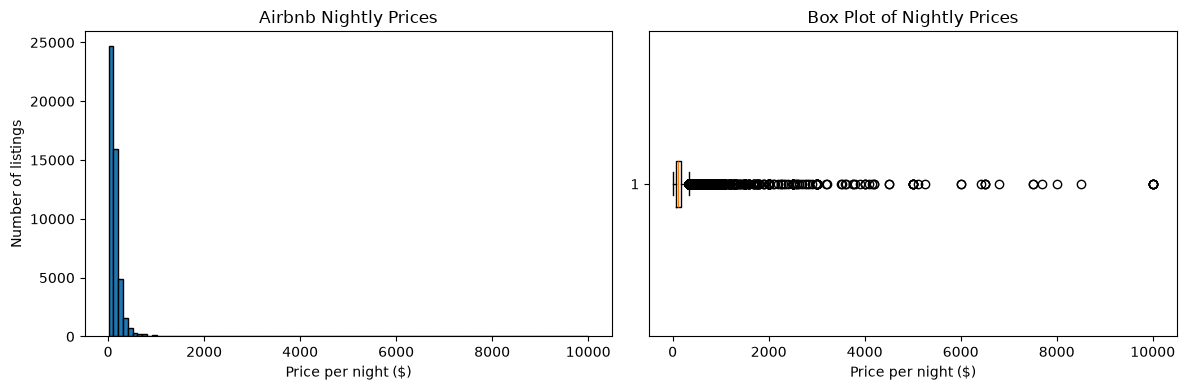

In [17]:
import matplotlib.pyplot as plt

# Keep positive prices for this analysis
airbnb_positive = airbnb[airbnb["price"] > 0].copy()

print("Original listings:", len(airbnb))
print("Positive-price listings:", len(airbnb_positive))
print("Listings excluded:", len(airbnb) - len(airbnb_positive))

print("\nPositive-price summary:")
print(airbnb_positive["price"].describe())

# Show the full price distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    airbnb_positive["price"],
    bins=100,
    edgecolor="black"
)
axes[0].set_title("Airbnb Nightly Prices")
axes[0].set_xlabel("Price per night ($)")
axes[0].set_ylabel("Number of listings")

axes[1].boxplot(
    airbnb_positive["price"],
    orientation="horizontal"
)
axes[1].set_title("Box Plot of Nightly Prices")
axes[1].set_xlabel("Price per night ($)")

plt.tight_layout()
plt.show()

### Method 1: Interquartile Range (IQR)

The IQR measures the spread of the middle 50% of prices.

Q1 is the 25th percentile, and Q3 is the 75th percentile.

IQR = Q3 - Q1

I will flag prices outside these boundaries:

- Lower boundary = Q1 - 1.5 × IQR
- Upper boundary = Q3 + 1.5 × IQR

For this dataset, Q1 is $69 and Q3 is $175, giving an IQR of $106.
The boundaries are -$90 and $334.

Because I already excluded non-positive prices, this rule will
only remove listings priced above $334.

IQR is less affected by extreme prices than the mean and standard
deviation. However, it can still flag genuine expensive listings.
These are statistical outliers under this rule, not confirmed errors.

In [11]:
# Calculate quartiles and the IQR
Q1 = airbnb_positive["price"].quantile(0.25)
Q3 = airbnb_positive["price"].quantile(0.75)
IQR = Q3 - Q1

# Calculate the outlier boundaries
iqr_lower = Q1 - 1.5 * IQR
iqr_upper = Q3 + 1.5 * IQR

# Keep prices inside the boundaries
iqr_data = airbnb_positive[
    airbnb_positive["price"].between(iqr_lower, iqr_upper)
].copy()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", iqr_lower)
print("Upper boundary:", iqr_upper)

print("\nListings kept:", len(iqr_data))
print("Listings removed:", len(airbnb_positive) - len(iqr_data))

print("\nPrice summary after IQR filtering:")
print(iqr_data["price"].describe())

Q1: 69.0
Q3: 175.0
IQR: 106.0
Lower boundary: -90.0
Upper boundary: 334.0

Listings kept: 45912
Listings removed: 2972

Price summary after IQR filtering:
count    45912.000000
mean       119.999063
std         68.133003
min         10.000000
25%         65.000000
50%        100.000000
75%        159.000000
max        334.000000
Name: price, dtype: float64


### IQR Results

The IQR boundaries were -$90 and $334. Applying these boundaries
to the positive-price dataset removed 2,972 listings and kept 45,912.

The mean price decreased from approximately $152.76 to $120.00.
The median decreased from $106 to $100, while the standard
deviation decreased from approximately $240.17 to $68.13.

The larger change in the mean shows that high prices had a strong
effect on the average. The smaller change in the median shows
that it was less affected by these extreme prices.

The retained prices satisfy the boundaries calculated from the
original positive-price dataset.

### Method 2: Mean and Standard Deviation

The mean measures the average price. Standard deviation measures
how spread out the prices are around that average.

I will keep prices within three standard deviations of the mean:

- Lower boundary = mean - 3 × standard deviation
- Upper boundary = mean + 3 × standard deviation

This is equivalent to keeping prices with an absolute z-score
of at most 3, using the same mean and standard deviation.

This rule is often used for approximately bell-shaped data.
Airbnb prices are right-skewed, so I will use it as a comparison.
Extreme prices can increase both the mean and standard deviation,
making the boundaries wider.

I will apply this method to the same positive-price dataset used
for IQR, so the methods can be compared fairly.

In [12]:
# Calculate the mean and standard deviation
mean_price = airbnb_positive["price"].mean()
std_price = airbnb_positive["price"].std()

# Calculate boundaries
std_lower = mean_price - 3 * std_price
std_upper = mean_price + 3 * std_price

# Keep prices within the boundaries
std_data = airbnb_positive[
    airbnb_positive["price"].between(std_lower, std_upper)
].copy()

print("Mean price:", round(mean_price, 2))
print("Standard deviation:", round(std_price, 2))
print("Lower boundary:", round(std_lower, 2))
print("Upper boundary:", round(std_upper, 2))

print("\nListings kept:", len(std_data))
print("Listings removed:", len(airbnb_positive) - len(std_data))

print("\nPrice summary after filtering:")
print(std_data["price"].describe())

Mean price: 152.76
Standard deviation: 240.17
Lower boundary: -567.76
Upper boundary: 873.27

Listings kept: 48496
Listings removed: 388

Price summary after filtering:
count    48496.000000
mean       138.778373
std        107.550128
min         10.000000
25%         69.000000
50%        105.000000
75%        175.000000
max        860.000000
Name: price, dtype: float64


### Mean and Standard Deviation Results

The boundaries were approximately -$567.76 and $873.27.
This method removed 388 listings and kept 48,496.

After filtering, the mean price was approximately $138.78,
the median was $105, and the standard deviation was $107.55.
The highest retained price was $860.

This method removed fewer listings than IQR because its upper
boundary was much higher. The original extreme prices increased
the mean and standard deviation, creating a wider accepted range.

### Method 3: Percentile Filtering

A percentile describes a position in sorted data.
For example, the 99th percentile is a value at or below which
approximately 99% of observations fall.

I will keep prices between the 1st and 99th percentiles,
including the boundary values.

This method does not require a bell-shaped distribution.
However, the choice of 1% and 99% is a decision made for this
comparison, rather than proof that values outside are errors.

The percentage removed may differ from exactly 2% because
multiple listings can have the same boundary price.
This method may also exclude genuine low-price listings.

In [13]:
# Calculate the percentile boundaries
percentile_lower = airbnb_positive["price"].quantile(0.01)
percentile_upper = airbnb_positive["price"].quantile(0.99)

# Keep prices inside the boundaries
percentile_data = airbnb_positive[
    airbnb_positive["price"].between(
        percentile_lower,
        percentile_upper
    )
].copy()

print("1st percentile:", round(percentile_lower, 2))
print("99th percentile:", round(percentile_upper, 2))

print("\nListings kept:", len(percentile_data))
print("Listings removed:", len(airbnb_positive) - len(percentile_data))

print("\nPrice summary after percentile filtering:")
print(percentile_data["price"].describe())

1st percentile: 30.0
99th percentile: 799.0

Listings kept: 48017
Listings removed: 867

Price summary after percentile filtering:
count    48017.000000
mean       138.502010
std        103.694011
min         30.000000
25%         70.000000
50%        105.000000
75%        175.000000
max        799.000000
Name: price, dtype: float64


### Percentile Results

The 1st percentile was $30, and the 99th percentile was $799.
Keeping prices within these boundaries removed 867 listings
and retained 48,017.

The mean after filtering was approximately $138.50, and the
median was $105. This method removed prices from both ends,
including potentially genuine inexpensive listings below $30.

### Comparing the Methods and Choosing a Final Dataset

The three methods produced different results:

- IQR removed 2,972 listings.
- Mean plus or minus three standard deviations removed 388 listings.
- The 1st-to-99th-percentile method removed 867 listings.

I selected IQR for my final price-filtered dataset because
the prices were right-skewed and quartiles are less affected
by extreme prices than the mean and standard deviation.

The final dataset contains 45,912 listings priced from $10 to $334.

This is a dataset with no price outliers under the original
IQR boundaries used in this analysis. It does not mean that
every possible outlier has been removed under every method.

A limitation is that one citywide rule may remove genuine luxury
listings. Prices also differ by neighbourhood and room type,
so calculating boundaries within comparable groups could be
a useful improvement.

The mean and median describe typical prices, but neither is
an outlier-removal rule on its own. A boundary rule is needed
to decide which listings to exclude.

In [14]:
# Compare each method using the same starting dataset
datasets = {
    "Positive prices": airbnb_positive,
    "IQR": iqr_data,
    "Mean ± 3 standard deviations": std_data,
    "1st–99th percentiles": percentile_data
}

comparison_rows = []

for method, dataset in datasets.items():
    comparison_rows.append({
        "Method": method,
        "Listings kept": len(dataset),
        "Listings removed": len(airbnb_positive) - len(dataset),
        "Mean price": dataset["price"].mean(),
        "Median price": dataset["price"].median(),
        "Standard deviation": dataset["price"].std(),
        "Minimum price": dataset["price"].min(),
        "Maximum price": dataset["price"].max()
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(2))

# Select the final dataset
airbnb_clean = iqr_data.copy()

# Verify using the original IQR boundaries
outside_boundaries = (
    ~airbnb_clean["price"].between(iqr_lower, iqr_upper)
).sum()

print("\nFinal number of listings:", len(airbnb_clean))
print("Prices outside the original IQR boundaries:", outside_boundaries)

,Method,Listings kept,Listings removed,Mean price,Median price,Standard deviation,Minimum price,Maximum price
0,Positive prices,48884,0,152.76,106.0,240.17,10,10000
1,IQR,45912,2972,120.00,100.0,68.13,10,334
2,Mean ± 3 standard deviations,48496,388,138.78,105.0,107.55,10,860
3,1st–99th percentiles,48017,867,138.50,105.0,103.69,30,799



Final number of listings: 45912
Prices outside the original IQR boundaries: 0


### Comparing Prices Before and After Filtering

The following histograms compare positive nightly prices before
filtering with the prices retained by the IQR rule.

Both plots use the same price ranges and axis scales so they
can be compared fairly. I will display prices up to $1,000
to make the main distribution easier to see. The original
dataset also contains prices above this display limit.

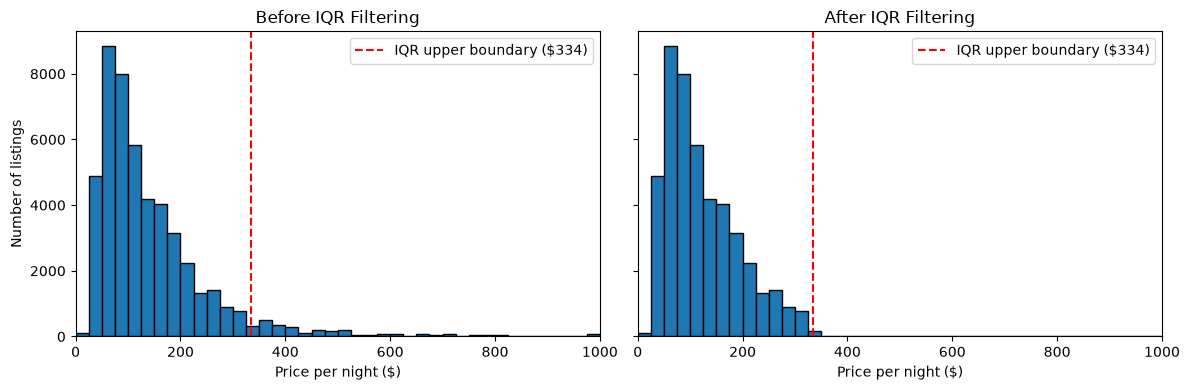

Before-filtering listings above the plot's $1,000 limit: 239


In [15]:
# Use matching bins and scales for a fair comparison
price_bins = range(0, 1001, 25)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    sharex=True,
    sharey=True
)

axes[0].hist(
    airbnb_positive["price"],
    bins=price_bins,
    edgecolor="black"
)
axes[0].set_title("Before IQR Filtering")
axes[0].set_ylabel("Number of listings")

axes[1].hist(
    airbnb_clean["price"],
    bins=price_bins,
    edgecolor="black"
)
axes[1].set_title("After IQR Filtering")

for axis in axes:
    axis.set_xlabel("Price per night ($)")
    axis.set_xlim(0, 1000)
    axis.axvline(
        iqr_upper,
        color="red",
        linestyle="--",
        label="IQR upper boundary ($334)"
    )
    axis.legend()

plt.tight_layout()
plt.show()

print(
    "Before-filtering listings above the plot's $1,000 limit:",
    (airbnb_positive["price"] > 1000).sum()
)

### Saving the Cleaned Dataset

I will save the final price-filtered dataset as
airbnb_cleaned_iqr.csv.

Starting with 48,895 listings, I excluded 11 zero-price listings
and 2,972 listings above the original IQR upper boundary.
This leaves 45,912 listings.

The cleaning focused on price. Missing values or other quality
issues in unrelated columns have not been addressed.

In [16]:
# Save without adding an extra row-index column
airbnb_clean.to_csv("airbnb_cleaned_iqr.csv", index=False)

print("Saved: airbnb_cleaned_iqr.csv")

Saved: airbnb_cleaned_iqr.csv


## Final Reflection

In Part A, I learned how to turn email text into word counts,
train two Naive Bayes models, and evaluate their predictions.

Gaussian Naive Bayes achieved 94.59% accuracy, while Multinomial
Naive Bayes achieved 94.19%. Gaussian Naive Bayes performed
slightly better on this test set, although both models made
mistakes.

I also learned why accuracy alone is not enough. Precision,
recall, and confusion matrices helped me understand missed
spam and genuine emails incorrectly flagged as spam.

In Part B, I compared IQR, mean with standard deviation,
and percentile filtering. These methods removed different
numbers of listings because they used different boundaries.

I selected the IQR-filtered dataset for examining typical prices.
The final dataset contains 45,912 listings, with a mean price
of approximately $120 and a median price of $100.

My main learning is that an outlier depends on the rule and
context. A high price can be unusual without being incorrect.
Filtering decisions should therefore be explained clearly.

## References

- Lab instructions and datasets:
  https://github.com/aaiml/CSCN8000-lab-submissions/blob/main/practical_labs/Lab2.md
- GitHub Pages setup guide:
  https://docs.github.com/en/pages/quickstart